In [ ]:
# to ignore the warnings
import warnings
warnings.filterwarnings("ignore")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!unzip '/content/drive/MyDrive/PROJECT_DATASETS/Pest_train1.zip'

unzip:  cannot find or open /content/drive/MyDrive/PROJECT_DATASETS/Pest_train1.zip, /content/drive/MyDrive/PROJECT_DATASETS/Pest_train1.zip.zip or /content/drive/MyDrive/PROJECT_DATASETS/Pest_train1.zip.ZIP.


In [ ]:
import pandas as pd
import numpy as np
import os
import shutil
import glob
import matplotlib.pyplot as plt

In [ ]:
train_path  = "/content/pest/train"
#valid_path  = ""
test_path   = "/content/pest/test"
print("splited")

splited


In [ ]:

from keras.preprocessing.image import ImageDataGenerator
from keras.applications import vgg16
from keras.models import Model
from keras.layers import Dense, MaxPool2D, Conv2D
import keras

ImportError: cannot import name 'ImageDataGenerator' from 'keras.preprocessing.image' (/usr/local/lib/python3.12/dist-packages/keras/preprocessing/image/__init__.py)

In [ ]:
train_data_gen = ImageDataGenerator(preprocessing_function= vgg16.preprocess_input , zoom_range= 0.2, horizontal_flip= True, shear_range= 0.2 , rescale= 1./255)
train = train_data_gen.flow_from_directory(directory= train_path , target_size=(224,224))

Found 2700 images belonging to 9 classes.


In [ ]:
test_data_gen = ImageDataGenerator(preprocessing_function= vgg16.preprocess_input, rescale= 1./255 )
test = train_data_gen.flow_from_directory(directory= test_path , target_size=(224,224), shuffle= False)

Found 450 images belonging to 9 classes.


In [ ]:
train.class_indices

{'aphids': 0,
 'armyworm': 1,
 'beetle': 2,
 'bollworm': 3,
 'grasshopper': 4,
 'mites': 5,
 'mosquito': 6,
 'sawfly': 7,
 'stem_borer': 8}

In [ ]:
class_type = {0:'aphids',
 1:'armyworm',
 2:'beetle',
 3:'bollworm',
 4:'grasshopper',
 5:'mites',
 6:'mosquito',
 7:'sawfly',
 8:'stem_borer'}

In [ ]:
t_img , label = train.next()

In [ ]:
def plotImages(img_arr, label):

  for im, l in zip(img_arr,label) :
    plt.figure(figsize= (5,5))
    plt.imshow(im, cmap = 'gray')
    plt.title(im.shape)
    plt.axis = False
    plt.show()

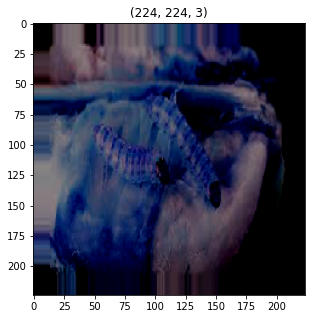

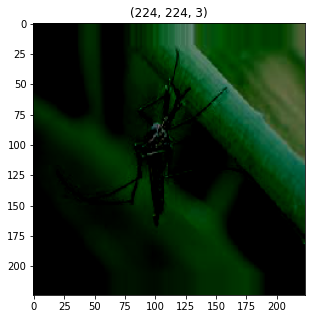

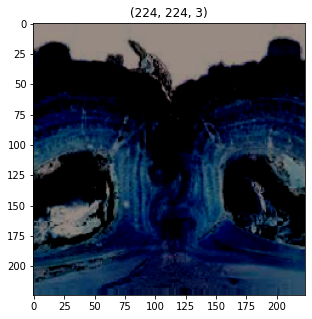

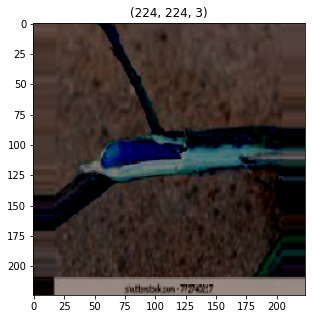

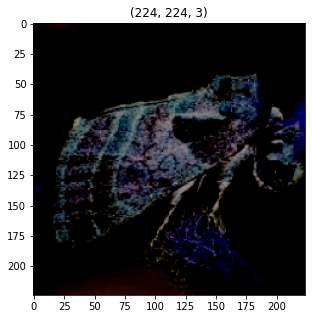

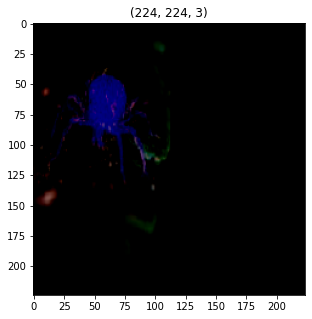

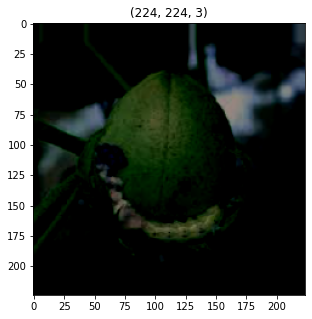

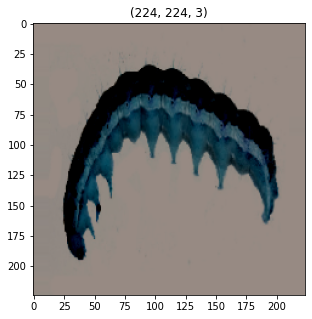

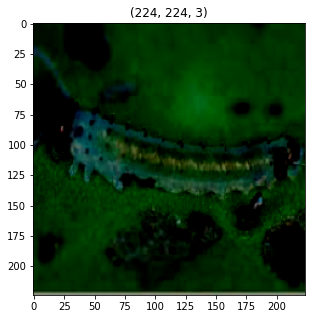

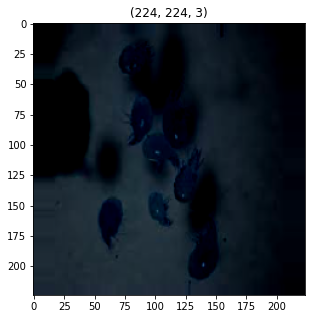

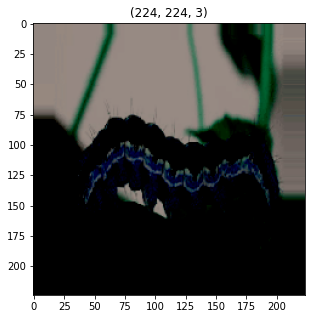

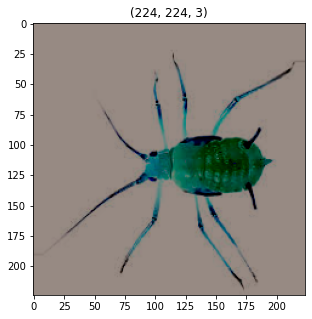

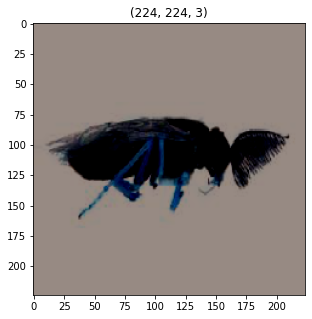

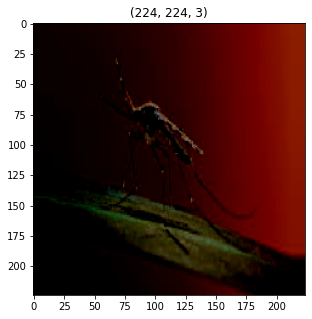

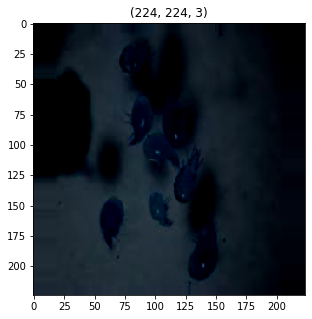

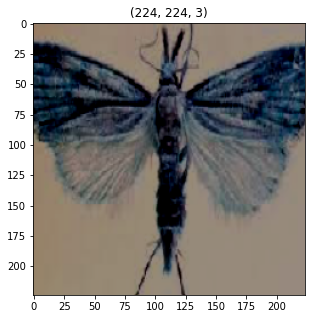

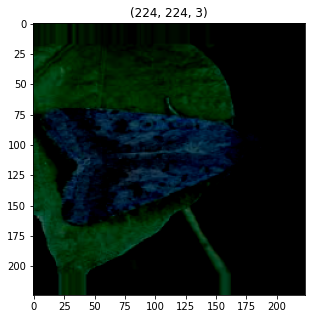

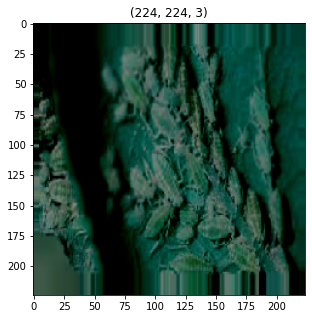

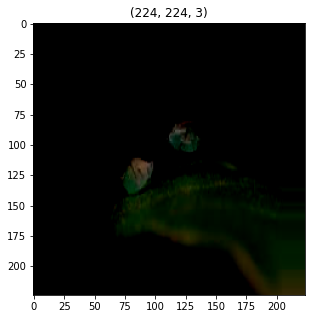

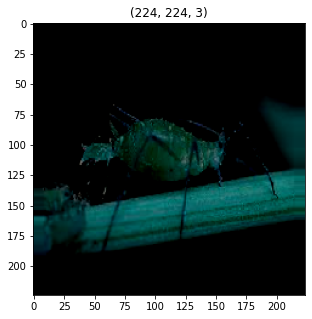

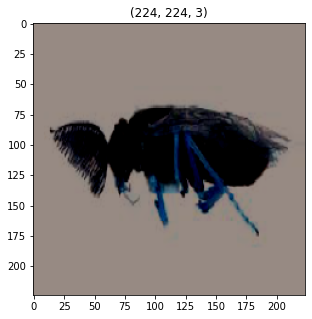

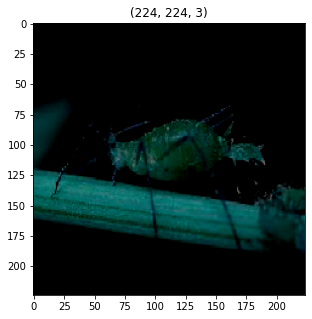

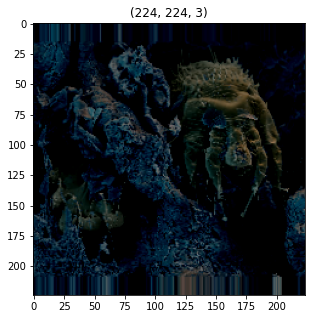

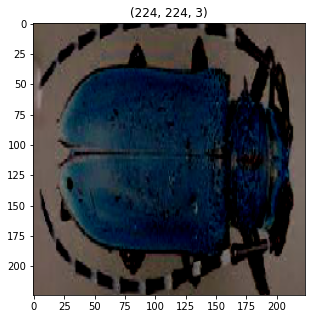

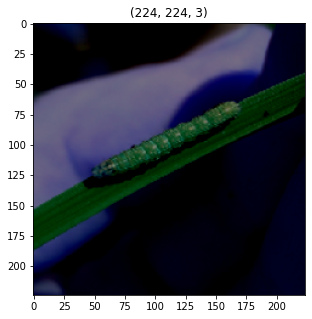

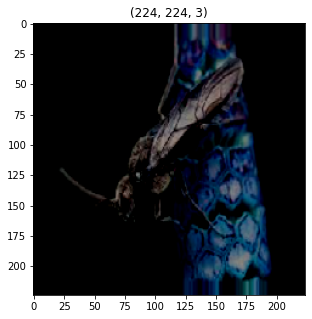

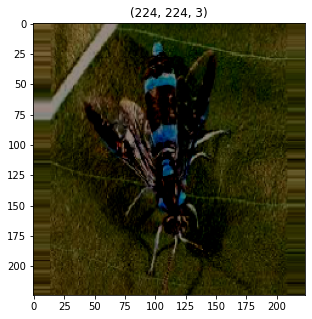

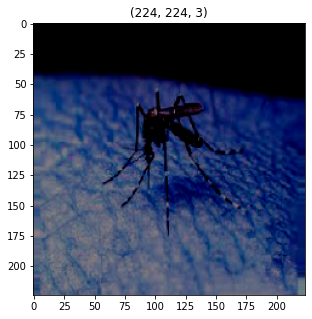

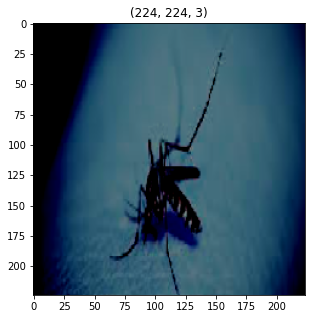

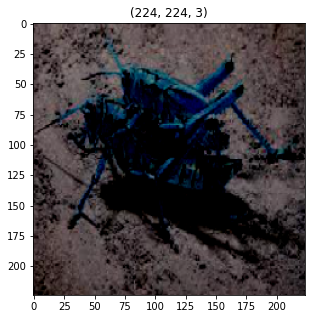

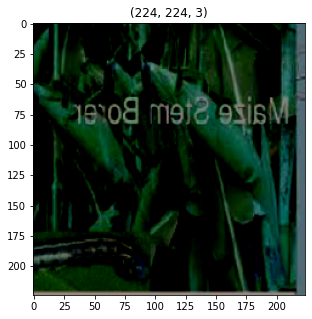

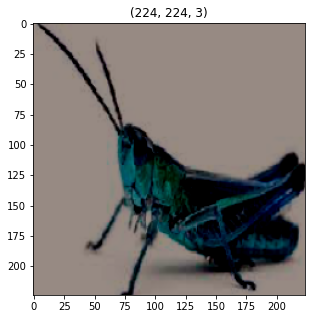

In [ ]:
plotImages(t_img, label)

In [ ]:
from keras.applications.vgg16 import VGG16
from keras.layers import Flatten , Dense, Dropout , MaxPool2D

In [ ]:
from keras.applications.vgg16 import VGG16
from keras.layers import Flatten , Dense, Dropout , MaxPool2D

In [ ]:
vgg = VGG16( input_shape=(224,224,3), include_top= False) # include_top will consider the new weights

58889256/58889256 [==============================] - 3s 0us/step


In [ ]:
for layer in vgg.layers:           # Dont Train the parameters again
  layer.trainable = False

In [ ]:
x = Flatten()(vgg.output)
x = Dense(units=9, activation='softmax', name = 'predictions')(x)

model = Model(vgg.input, x)

In [ ]:
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 224, 224, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 224, 224, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 112, 112, 64)      0         
                                                                 
 block2_conv1 (Conv2D)       (None, 112, 112, 128)     73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 112, 112, 128)     147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 56, 56, 128)       0     

In [ ]:
model.compile(optimizer='adam', loss = 'categorical_crossentropy', metrics=['accuracy'])

In [ ]:
# implementing early stopping and model check point

from keras.callbacks import EarlyStopping
from keras.callbacks import ModelCheckpoint

es = EarlyStopping(monitor= "val_accuracy" , min_delta= 0.01, patience= 3, verbose=1)
mc = ModelCheckpoint(filepath="bestmodel.h5", monitor="val_accuracy", verbose=1, save_best_only= False)

In [ ]:
#hist = model.fit_generator(train, steps_per_epoch= 10, epochs= 8, validation_data= valid , validation_steps= 32)
hist = model.fit_generator(train, steps_per_epoch= 10, epochs=20 , validation_data= test , validation_steps= 32, callbacks=[mc])

Epoch 1/20
10/10 [==============================] - ETA: 0s - loss: 2.9077 - accuracy: 0.2031


Epoch 1: saving model to bestmodel.h5
10/10 [==============================] - 23s 1s/step - loss: 2.9077 - accuracy: 0.2031 - val_loss: 1.6936 - val_accuracy: 0.4267
Epoch 2/20
10/10 [==============================] - ETA: 0s - loss: 1.5492 - accuracy: 0.5063
Epoch 2: saving model to bestmodel.h5
10/10 [==============================] - 4s 408ms/step - loss: 1.5492 - accuracy: 0.5063
Epoch 3/20
10/10 [==============================] - ETA: 0s - loss: 1.0661 - accuracy: 0.6531
Epoch 3: saving model to bestmodel.h5
10/10 [==============================] - 5s 439ms/step - loss: 1.0661 - accuracy: 0.6531
Epoch 4/20
10/10 [==============================] - ETA: 0s - loss: 1.0483 - accuracy: 0.6687
Epoch 4: saving model to bestmodel.h5
10/10 [==============================] - 4s 431ms/step - loss: 1.0483 - accuracy: 0.6687
Epoch 5/20
10/10 [==============================] - ETA: 0s - loss: 0.7280 - accuracy: 0.7781
Epoch 5: saving model to bestmodel.h5
10/10 [==============================

In [ ]:
## load only the best model
from keras.models import load_model
model = load_model("bestmodel.h5")

In [ ]:
h = hist.history
h.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

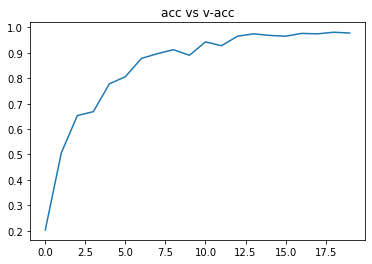

In [ ]:
plt.plot(h['accuracy'])
plt.plot(h['val_accuracy'] , c = "red")
plt.title("acc vs v-acc")
plt.show()

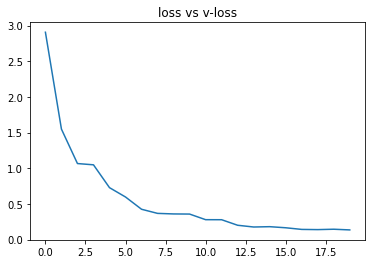

In [ ]:
plt.plot(h['loss'])
plt.plot(h['val_loss'] , c = "red")
plt.title("loss vs v-loss")
plt.show()

In [ ]:
# checking out the accuracy of our model

acc = model.evaluate_generator(generator= test)[1]

print(f"The accuracy of your model is = {acc} %")

The accuracy of your model is = 0.9644444584846497 %


In [ ]:
from keras.preprocessing import image

def get_img_array(img_path):
  """
  Input : Takes in image path as input
  Output : Gives out Pre-Processed image
  """
  path = img_path

  img = keras.utils.load_img(path, target_size=(224,224,3))

  img = keras.utils.img_to_array(img)/255
  img = np.expand_dims(img , axis= 0 )

  return img

1/1 [==============================] - 1s 789ms/step
The given  image is of type = bollworm



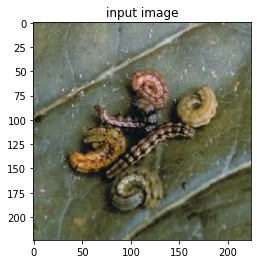

In [ ]:
# path for that new image. ( you can take it either from google or any other scource)

path = "/content/pest/train/bollworm/jpg_11.jpg"       # you can add any image path

#predictions: path:- provide any image from google or provide image from all image folder
img = get_img_array(path)

res = class_type[np.argmax(model.predict(img))]
print(f"The given  image is of type = {res}")
print()

# to display the image
plt.imshow(img[0], cmap = "gray")
plt.title("input image")
plt.show()

1/1 [==============================] - 0s 17ms/step
The given  image is of type = beetle



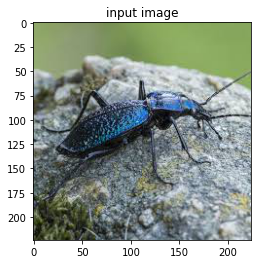

In [ ]:

path = "/content/pest/train/beetle/jpg_1.jpg"       # you can add any image path

#predictions: path:- provide any image from google or provide image from all image folder
img = get_img_array(path)

res = class_type[np.argmax(model.predict(img))]
print(f"The given  image is of type = {res}")
print()

# to display the image
plt.imshow(img[0], cmap = "gray")
plt.title("input image")
plt.show()

1/1 [==============================] - 0s 18ms/step
The given  image is of type = aphids



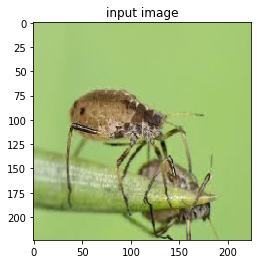

In [ ]:

path = "/content/pest/train/aphids/jpg_1.jpg"       # you can add any image path

#predictions: path:- provide any image from google or provide image from all image folder
img = get_img_array(path)

res = class_type[np.argmax(model.predict(img))]
print(f"The given  image is of type = {res}")
print()

# to display the image
plt.imshow(img[0], cmap = "gray")
plt.title("input image")
plt.show()

1/1 [==============================] - 0s 16ms/step
The given  image is of type = armyworm



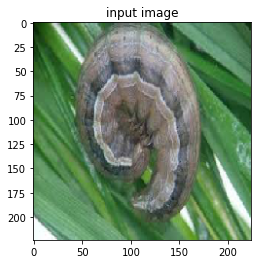

In [ ]:

path = "/content/pest/train/armyworm/jpg_11.jpg"       # you can add any image path

#predictions: path:- provide any image from google or provide image from all image folder
img = get_img_array(path)

res = class_type[np.argmax(model.predict(img))]
print(f"The given  image is of type = {res}")
print()

# to display the image
plt.imshow(img[0], cmap = "gray")
plt.title("input image")
plt.show()

1/1 [==============================] - 0s 25ms/step
The given  image is of type = grasshopper



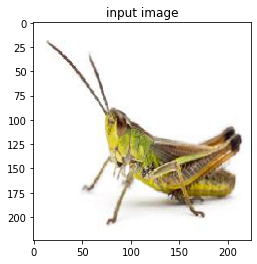

In [ ]:

path = "/content/pest/train/grasshopper/jpg_1.jpg"       # you can add any image path

#predictions: path:- provide any image from google or provide image from all image folder
img = get_img_array(path)

res = class_type[np.argmax(model.predict(img))]
print(f"The given  image is of type = {res}")
print()

# to display the image
plt.imshow(img[0], cmap = "gray")
plt.title("input image")
plt.show()

1/1 [==============================] - 0s 15ms/step
The given  image is of type = mites



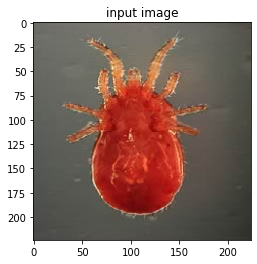

In [ ]:

path = "/content/pest/train/mites/jpg_1.jpg"       # you can add any image path

#predictions: path:- provide any image from google or provide image from all image folder
img = get_img_array(path)

res = class_type[np.argmax(model.predict(img))]
print(f"The given  image is of type = {res}")
print()

# to display the image
plt.imshow(img[0], cmap = "gray")
plt.title("input image")
plt.show()

1/1 [==============================] - 0s 15ms/step
The given  image is of type = mosquito



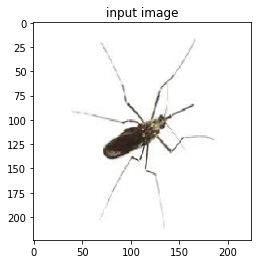

In [ ]:

path = "/content/pest/train/mosquito/jpg_1.jpg"       # you can add any image path

#predictions: path:- provide any image from google or provide image from all image folder
img = get_img_array(path)

res = class_type[np.argmax(model.predict(img))]
print(f"The given  image is of type = {res}")
print()

# to display the image
plt.imshow(img[0], cmap = "gray")
plt.title("input image")
plt.show()

1/1 [==============================] - 0s 17ms/step
The given  image is of type = sawfly



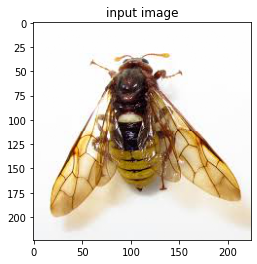

In [ ]:

path = "/content/pest/train/sawfly/jpg_1.jpg"       # you can add any image path

#predictions: path:- provide any image from google or provide image from all image folder
img = get_img_array(path)

res = class_type[np.argmax(model.predict(img))]
print(f"The given  image is of type = {res}")
print()

# to display the image
plt.imshow(img[0], cmap = "gray")
plt.title("input image")
plt.show()

1/1 [==============================] - 0s 17ms/step
The given  image is of type = stem_borer



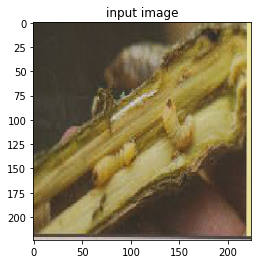

In [ ]:

path = "/content/pest/train/stem_borer/jpg_1.jpg"       # you can add any image path

#predictions: path:- provide any image from google or provide image from all image folder
img = get_img_array(path)

res = class_type[np.argmax(model.predict(img))]
print(f"The given  image is of type = {res}")
print()

# to display the image
plt.imshow(img[0], cmap = "gray")
plt.title("input image")
plt.show()